In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Аттракторы детерминированной модели

In [2]:
from stochastique.core.dynamic import DynamicSystem2D
from stochastique.util.plot import legend_unique_labels
from stochastique.models.SN import model_SN, equilibria_SN

In [3]:
SN = DynamicSystem2D(
    model_SN,
    params=dict(a=1, b=2)
)

Text(0.5, 1.0, 'SN bifurcation diagram ($x_0^{(1)}$ = [0. 0.], $x_0^{(2)}$ = [1.4 1.4], $x_0^{(3)}$ = [-1.4 -1.4])')

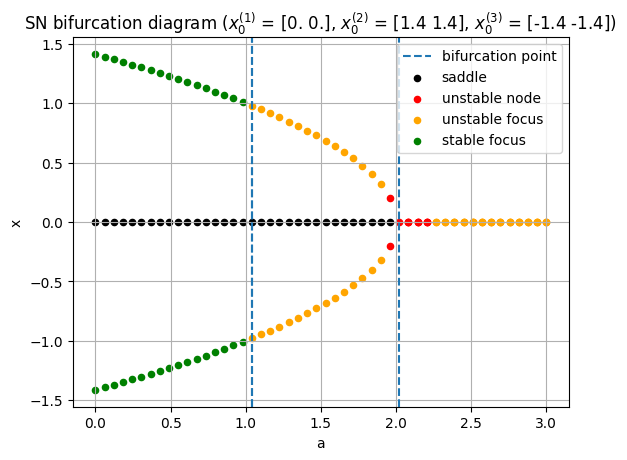

In [4]:
param_name = 'a'
param_values = np.linspace(0, 3, num=50)

b = 2
states_init = [
    lambda a: np.array([0., 0.]),
    lambda a: np.array([np.sqrt(b - a), np.sqrt(b - a)]),
    lambda a: -np.array([np.sqrt(b - a), np.sqrt(b - a)])
]
equilibria_per_state = []
bif_points_per_state = []

fig, ax = plt.subplots()

for state_init in states_init:
    bifurcation_points, equilibria = SN.plot_bifurcation_diagram(
        param_name=param_name,
        param_values=param_values,
        state_init=state_init,
        ax=ax
    )

legend_unique_labels(ax)

ax.set_title(
    r'SN bifurcation diagram ('
    '$x_0^{(1)}$ = '
    f'{np.round(states_init[0](0), 1)}, '
    '$x_0^{(2)}$ = '
    f'{np.round(states_init[1](0), 1)}, '
    '$x_0^{(3)}$ = '
    f'{np.round(states_init[2](0), 1)})'
)

A) Изобразим 2 устойчивых равновесия при значениях параметра $a = 0.5$, $a = 7$.

Test trajectories and search cycles: 100%|██████████| 100/100 [00:01<00:00, 53.50it/s]
/tmp/ipykernel_73207/331323948.py:19: RuntimeWarning: invalid value encountered in sqrt
  np.array([np.sqrt(b - a), np.sqrt(b - a)]),
/tmp/ipykernel_73207/331323948.py:20: RuntimeWarning: invalid value encountered in sqrt
  np.array([-np.sqrt(b - a), -np.sqrt(b - a)])


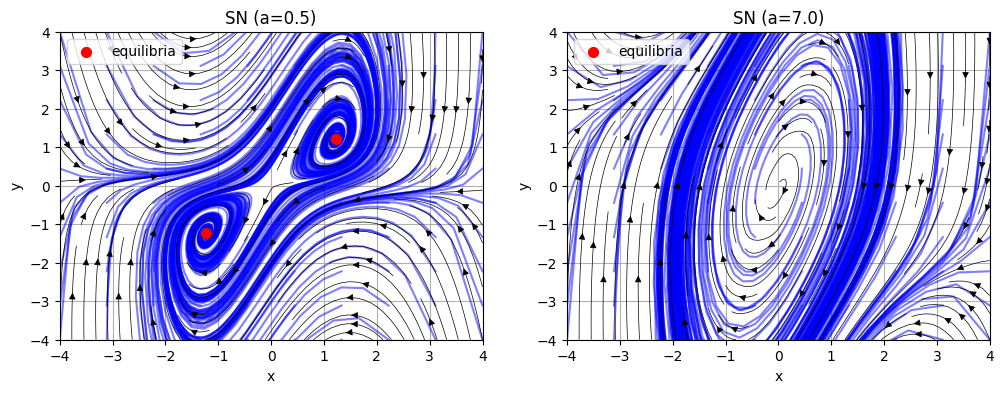

In [5]:
time_span = np.linspace(0, 100, num=10 ** 3)

a_values = [0.5, 7]

fig, axes = plt.subplots(1, len(a_values), figsize=(12, 4))

for ax, a in zip(axes, a_values):
    SN.params['a'] = a
    SN.plot_phase_portrait_dense(
        ax=ax,
        time_span=time_span,
        bounds=(-4, 4),
        grid_size=10,
        seacrh_limit_cycles=False,
    )

    equilibrium_points_all = [
        # np.array([0, 0]),
        np.array([np.sqrt(b - a), np.sqrt(b - a)]),
        np.array([-np.sqrt(b - a), -np.sqrt(b - a)])
    ]
    
    for point in equilibrium_points_all:
        ax.scatter(*point, color='red', marker='o', s=50, zorder=100, label='equilibria')
    
    ax.set_title(f"SN ({a=:.1f})")
    legend_unique_labels(ax, loc="upper left")

B) Изобразим 2 устойчивых равновесия, а также устойчивый и неустойчивый предельный цикл при значениях параметра $a = 0.715$, $a = 0.75$.

Test trajectories and search cycles:   0%|          | 0/100 [00:00<?, ?it/s]/mnt/data/vnts/projects/urfu/2026-spring_stochastic-analysis/src/stochastique/models/SN.py:23: RuntimeWarning: overflow encountered in scalar multiply
  -a * x + b * y - (x ** 2) * y
/mnt/data/vnts/projects/urfu/2026-spring_stochastic-analysis/src/stochastique/models/SN.py:23: RuntimeWarning: overflow encountered in scalar power
  -a * x + b * y - (x ** 2) * y
/mnt/data/vnts/projects/urfu/2026-spring_stochastic-analysis/src/stochastique/models/SN.py:23: RuntimeWarning: invalid value encountered in scalar subtract
  -a * x + b * y - (x ** 2) * y
Stable limit cycle found!: 100%|██████████| 100/100 [00:40<00:00,  2.45it/s] 


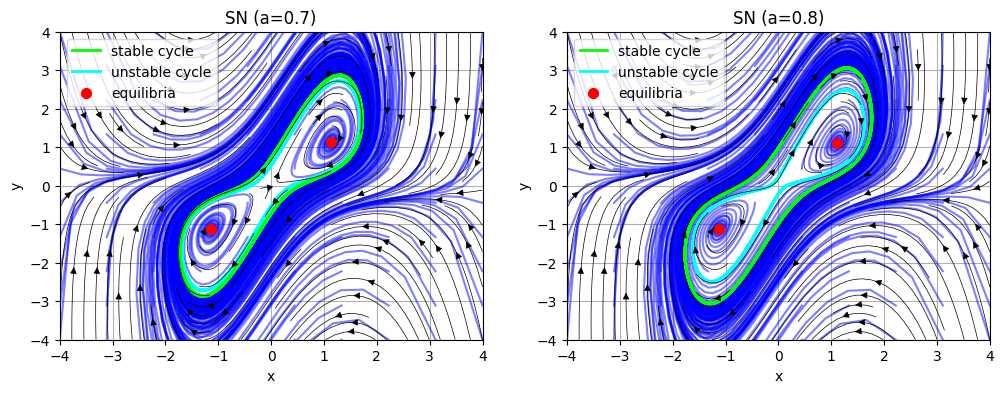

In [6]:
time_span = np.linspace(0, 100, num=10 ** 3)

a_values = [0.715, 0.75]

fig, axes = plt.subplots(1, len(a_values), figsize=(12, 4))

for ax, a in zip(axes, a_values):
    SN.params['a'] = a
    SN.plot_phase_portrait_dense(
        ax=ax,
        time_span=time_span,
        bounds=(-4, 4),
        grid_size=10,
        seacrh_limit_cycles=True,
    )

    equilibrium_points_all = [
        # np.array([0, 0]),
        np.array([np.sqrt(b - a), np.sqrt(b - a)]),
        np.array([-np.sqrt(b - a), -np.sqrt(b - a)])
    ]
    
    for point in equilibrium_points_all:
        ax.scatter(*point, color='red', marker='o', s=50, zorder=100, label='equilibria')
    
    legend_unique_labels(ax, loc="upper left")
    ax.set_title(f"SN ({a=:.1f})")

C)* Изобразим 2 устойчивых равновесия, а также устойчивый и 2 неустойчивых предельных цикла при значениях параметра $a = 0.8$, $a = 0.9$.

Test trajectories and search cycles:   0%|          | 0/100 [00:00<?, ?it/s]

Stable limit cycle found!: 100%|██████████| 100/100 [00:34<00:00,  2.90it/s] 


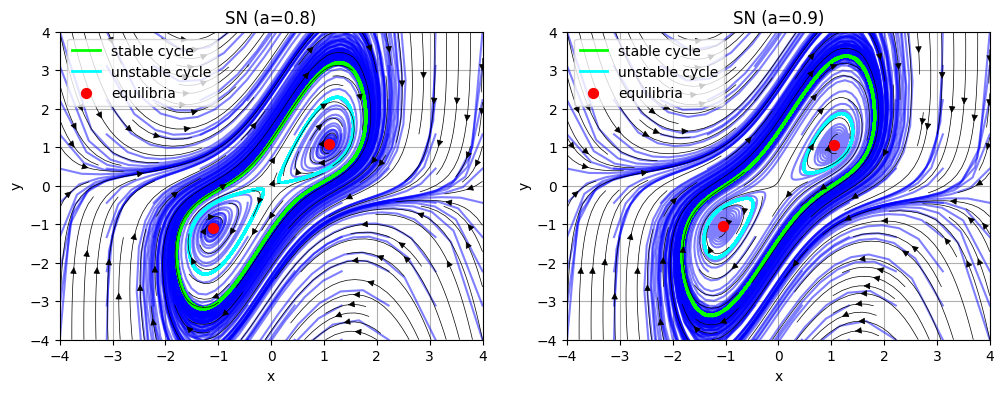

In [7]:
time_span = np.linspace(0, 100, num=10 ** 3)

a_values = [0.8, 0.9]

fig, axes = plt.subplots(1, len(a_values), figsize=(12, 4))

for ax, a in zip(axes, a_values):
    SN.params['a'] = a
    SN.plot_phase_portrait_dense(
        ax=ax,
        time_span=time_span,
        bounds=(-4, 4),
        grid_size=10,
        seacrh_limit_cycles=True,
    )

    equilibrium_points_all = [
        # np.array([0, 0]),
        np.array([np.sqrt(b - a), np.sqrt(b - a)]),
        np.array([-np.sqrt(b - a), -np.sqrt(b - a)])
    ]
    
    for point in equilibrium_points_all:
        ax.scatter(*point, color='red', marker='o', s=50, zorder=100, label='equilibria')
    
    legend_unique_labels(ax, loc="upper left")
    ax.set_title(f"SN ({a=:.1f})")

# Исследование ИШП между устойчивыми равновесиями $M_1$, $M_2$ для случая A

a) Локализуем бассейны притяжения равновесий $M_1$, $M_2$.

In [8]:
from stochastique.analysis.attraction import localize_basins_of_attraction

Localizing basins: 100%|██████████| 100/100 [03:03<00:00,  1.84s/it]


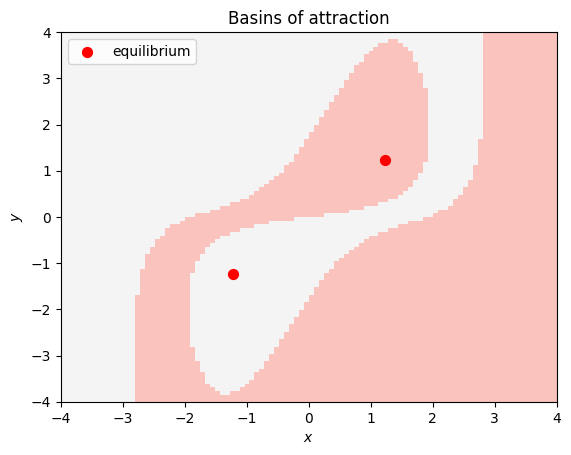

In [9]:
SN = DynamicSystem2D(
    model_SN,
    params=dict(a=0.5, b=2)
)

equilibria = equilibria_SN(a=0.5, b=2)

time_span = np.linspace(0, 100, num=10 ** 3)

fig, ax = plt.subplots()

localize_basins_of_attraction(
    system=SN,
    time_span=time_span,
    equilibria=equilibria,
    ax=ax,
    bounds=(-4, 4),
    grid_size=100,
)

equilibria_stable = [equilibria[0], equilibria[-1]]
for equilibrium_point in equilibria_stable:
    ax.scatter(*equilibrium_point, color='red', marker='o', s=50, zorder=100, label='equilibrium')

legend_unique_labels(ax, loc="upper left")

б) Построим доверительные эллипсы для равновесий $M_1$, $M_2$.

In [10]:
from stochastique.analysis.simulation import simulate_trajectory, simulate_stochastic_cloud
from stochastique.core.numerical import stochastic_sensitivity_matrix_2d
from stochastique.util.plot import plot_confidence_ellipse_2d

In [11]:
time_span = np.linspace(0, 100, num=10 ** 3)
noise_mask = np.array([1, 1])   # add noise to 1st equation only

a, b = None, 2
a_values = [
    0.5,
    # 7
]
eps_values = [
    0.01,
    0.1,
    0.2,
]

axes = [ax]
# fig, axes = plt.subplots(1, len(a_values))

# from collections.abc import Iterable
# axes = axes if isinstance(axes, Iterable) else [axes]

for ax, a in zip(axes, a_values):
    params = dict(a=a, b=b)
    equilibria = equilibria_SN(**params)
    equilibria_stable = [equilibria[0], equilibria[-1]]

    for eps in eps_values:
        for equilibrium in equilibria_stable:
            W = stochastic_sensitivity_matrix_2d(
                model_func=model_SN,
                params=params,
                equilibrium=equilibrium,
                noise_mask=noise_mask,
            )

            plot_confidence_ellipse_2d(
                ax=ax,
                equilibrium=equilibrium,
                W=W,
                epsilon=eps,
                major_axes=True,
            )

            simulate_stochastic_cloud(
                ax=ax,
                model_func=model_SN,
                params=params,
                state_init=equilibrium,
                time_span=time_span,
                epsilon=eps,
                noise_mask=noise_mask,
                num_simulations=10,
            )

        legend_unique_labels(ax)
        ax.set_title(rf'SN ($a$ = {a}, $b$ = {b}, $\varepsilon$ = {eps})')

Simulate system trajectories: 100%|██████████| 10/10 [00:00<00:00, 36.38it/s]


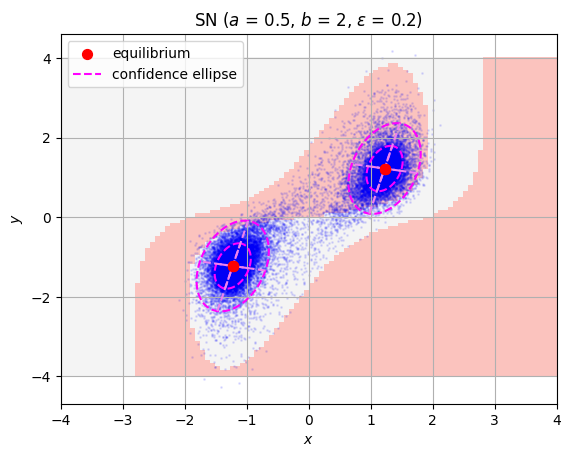

In [12]:
fig

в) Построим временные ряды для равновесий $M_1$, $M_2$.

In [13]:
from stochastique.analysis.simulation import simulate_trajectory, simulate_stochastic_cloud

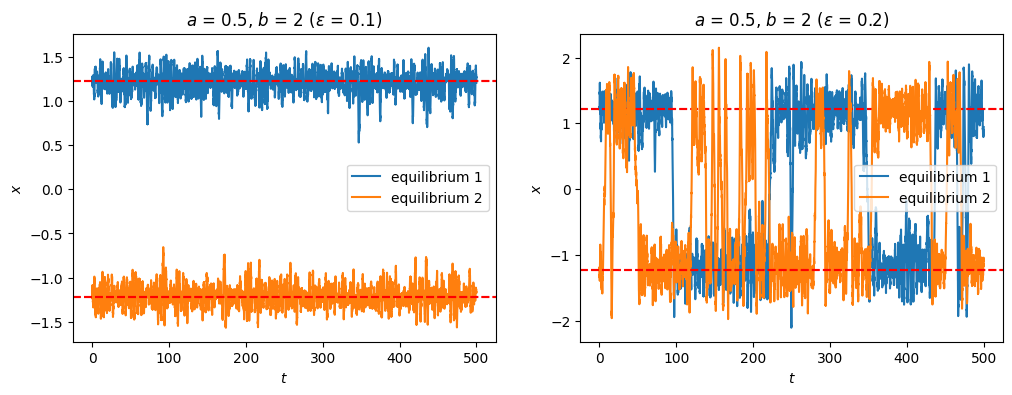

In [14]:
rng = np.random.default_rng()

time_span = np.linspace(0, 500, num=10 ** 4)
noise_mask = np.array([1, 1])   # add noise to 1st equation only

a, b = 0.5, 2
a_values = [
    0.5,
    # 7
]
eps_values = [
    0.1,
    0.2,
]

n_axes = len(eps_values)
fig, axes = plt.subplots(1, n_axes, figsize=(n_axes * 6, 4))

from collections.abc import Iterable
axes = axes if isinstance(axes, Iterable) else [axes]

for eps, ax in zip(eps_values, axes):
    params = dict(a=a, b=b)
    equilibria = equilibria_SN(**params)
    equilibria_stable = [equilibria[0], equilibria[-1]]

    for idx in range(len(equilibria_stable)):
        equilibrium = equilibria_stable[idx]
        trajectory = simulate_trajectory(
            model_func=model_SN,
            params=params,
            state_init=equilibrium,
            time_span=time_span,
            epsilon=eps,
            noise_mask=noise_mask,
            rng=rng,
        )
        # trajectory = trajectory[100:]   # clip transient
        trajectory_x = trajectory[:, 0]
        
        ax.plot(time_span, trajectory_x, label=f'equilibrium {idx + 1}')
        ax.axhline(equilibrium[0], color='red', linestyle='--')
        ax.axhline(equilibrium[1], color='red', linestyle='--')

    ax.set_title(rf'$a$ = {a}, $b$ = {b} ($\varepsilon$ = {eps})')
    ax.set_xlabel(r'$t$')
    ax.set_ylabel(r'$x$')
    legend_unique_labels(ax)

# Исследование ИШП между равновесиями и предельным циклом для случая C

In [15]:
from stochastique.analysis.simulation import simulate_trajectory, simulate_stochastic_cloud
from stochastique.core.numerical import stochastic_sensitivity_matrix_2d
from stochastique.util.plot import plot_confidence_ellipse_2d

Stable limit cycle found!: 100%|██████████| 100/100 [00:34<00:00,  2.87it/s] 


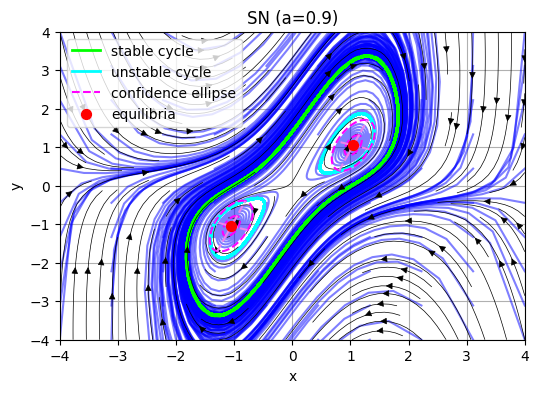

In [16]:
rng = np.random.default_rng()

time_span = np.linspace(0, 100, num=10 ** 3)
noise_mask = np.array([1, 1])   # add noise to 1st equation only

a_values = [0.9]
eps_values = [
    0.02,
    0.05,
]

n_axes = len(a_values)
fig, axes = plt.subplots(1, n_axes, figsize=(n_axes * 6, 4))

from collections.abc import Iterable
axes = axes if isinstance(axes, Iterable) else [axes]

for ax, a in zip(axes, a_values):
    params = dict(a=a, b=b)
    equilibria = equilibria_SN(**params)
    equilibria_stable = [equilibria[0], equilibria[-1]]
    
    SN.params['a'] = a
    SN.plot_phase_portrait_dense(
        ax=ax,
        time_span=time_span,
        bounds=(-4, 4),
        grid_size=10,
        seacrh_limit_cycles=True,
    )

    equilibrium_points_all = [
        # np.array([0, 0]),
        np.array([np.sqrt(b - a), np.sqrt(b - a)]),
        np.array([-np.sqrt(b - a), -np.sqrt(b - a)])
    ]

    for eps in eps_values:
        for equilibrium in equilibria_stable:
            W = stochastic_sensitivity_matrix_2d(
                model_func=model_SN,
                params=params,
                equilibrium=equilibrium,
                noise_mask=noise_mask,
            )

            plot_confidence_ellipse_2d(
                ax=ax,
                equilibrium=equilibrium,
                W=W,
                epsilon=eps,
                major_axes=True,
            )
    
    for point in equilibrium_points_all:
        ax.scatter(*point, color='red', marker='o', s=50, zorder=100, label='equilibria')
    
    legend_unique_labels(ax, loc="upper left")
    ax.set_title(f"SN ({a=:.1f})")

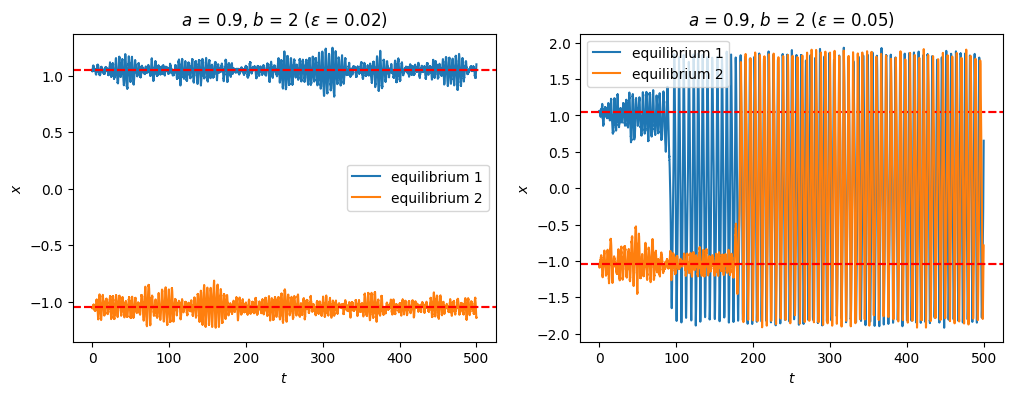

In [17]:
rng = np.random.default_rng()

time_span = np.linspace(0, 500, num=10 ** 4)
noise_mask = np.array([1, 1])   # add noise to 1st equation only

a, b = 0.9, 2
a_values = [
    0.9,
    # 7
]
eps_values = [
    0.02,
    0.05,
]

n_axes = len(eps_values)
fig, axes = plt.subplots(1, n_axes, figsize=(n_axes * 6, 4))

from collections.abc import Iterable
axes = axes if isinstance(axes, Iterable) else [axes]

for eps, ax in zip(eps_values, axes):
    params = dict(a=a, b=b)
    equilibria = equilibria_SN(**params)
    equilibria_stable = [equilibria[0], equilibria[-1]]

    for idx in range(len(equilibria_stable)):
        equilibrium = equilibria_stable[idx]
        trajectory = simulate_trajectory(
            model_func=model_SN,
            params=params,
            state_init=equilibrium,
            time_span=time_span,
            epsilon=eps,
            noise_mask=noise_mask,
            rng=rng,
        )
        # trajectory = trajectory[100:]   # clip transient
        trajectory_x = trajectory[:, 0]
        
        ax.plot(time_span, trajectory_x, label=f'equilibrium {idx + 1}')
        ax.axhline(equilibrium[0], color='red', linestyle='--')
        ax.axhline(equilibrium[1], color='red', linestyle='--')

    ax.set_title(rf'$a$ = {a}, $b$ = {b} ($\varepsilon$ = {eps})')
    ax.set_xlabel(r'$t$')
    ax.set_ylabel(r'$x$')
    legend_unique_labels(ax)